# 02 — Features NLP
Extraction des signaux NLP depuis le message texte (contribution originale).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))  # racine ml/ -> import src.*
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.features.nlp_extractor import extract_nlp_features, NLP_FEATURE_NAMES
from src.features.pipeline import load_dataset
print(len(NLP_FEATURE_NAMES), 'features NLP')

31 features NLP


## Test sur 3 messages exemples

In [2]:
samples = [
  'Nous voulons signer rapidement, budget 10000 TND, envoyez un devis urgent !',
  'Nous comparons plusieurs solutions, pouvez-vous arranger une demo ?',
  'Pas presse, je collecte juste des informations pour plus tard.']
for s in samples:
    f = extract_nlp_features(s)
    print(s[:50])
    print('  purchase_ready=%.2f urgency=%.2f budget=%.2f' % (f['purchase_ready_score'], f['urgency_score'], f['budget_score']))

Nous voulons signer rapidement, budget 10000 TND, 
  purchase_ready=0.33 urgency=0.67 budget=1.00
Nous comparons plusieurs solutions, pouvez-vous ar
  purchase_ready=0.00 urgency=0.00 budget=0.00
Pas presse, je collecte juste des informations pou
  purchase_ready=0.00 urgency=0.33 budget=0.00


## Application sur tout le dataset

In [3]:
df = load_dataset()
nlp = pd.DataFrame([extract_nlp_features(m) for m in df['message'].fillna('')])
nlp['converted'] = df['converted'].values
nlp.describe().T.head(15)

,count,mean,std,min,25%,50%,75%,max
word_count,5000.0,9.203200,1.563329,6.0000,8.0000,9.0000,10.0000,13.0000
sentence_count,5000.0,1.000000,0.000000,1.0000,1.0000,1.0000,1.0000,1.0000
avg_word_length,5000.0,5.297626,0.734359,3.4545,4.6667,5.4000,5.7500,6.8333
char_count,5000.0,58.218200,7.596560,45.0000,53.0000,56.0000,62.0000,74.0000
question_count,5000.0,0.563000,0.496065,0.0000,0.0000,1.0000,1.0000,1.0000
exclamation_count,5000.0,0.000000,0.000000,0.0000,0.0000,0.0000,0.0000,0.0000
uppercase_ratio,5000.0,0.021165,0.002683,0.0169,0.0196,0.0213,0.0238,0.0263
has_numbers,5000.0,0.000000,0.000000,0.0000,0.0000,0.0000,0.0000,0.0000
paragraph_count,5000.0,1.000000,0.000000,1.0000,1.0000,1.0000,1.0000,1.0000
urgency_score,5000.0,0.048462,0.117501,0.0000,0.0000,0.0000,0.0000,0.3333


## Distribution des scores d'intention

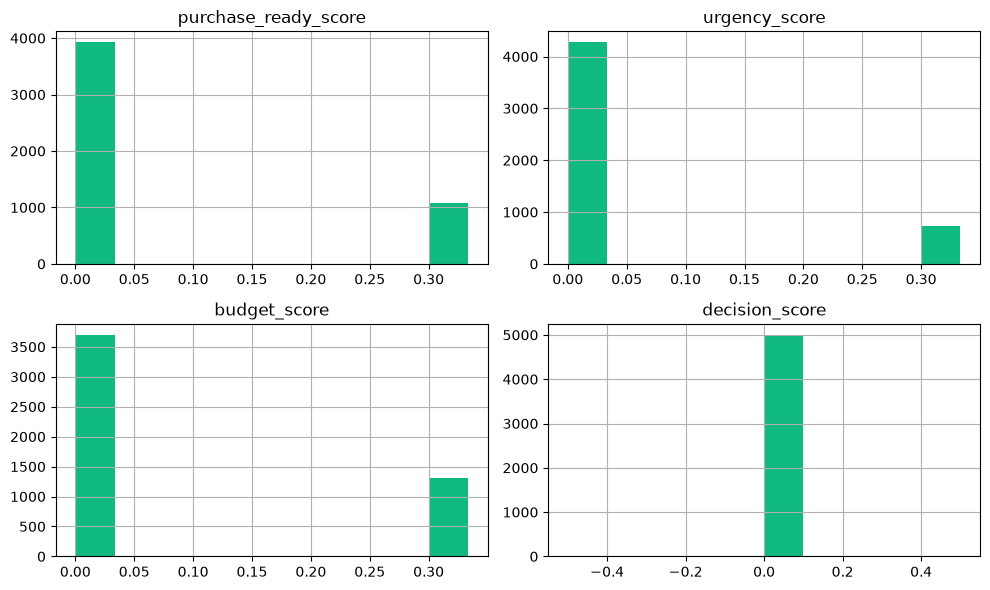

In [4]:
cols = ['purchase_ready_score','urgency_score','budget_score','decision_score']
nlp[cols].hist(bins=10, figsize=(10,6), color='#10b981'); plt.tight_layout(); plt.show()

## Corrélation features NLP vs conversion

In [5]:
corr = nlp.corr(numeric_only=True)['converted'].drop('converted').sort_values(ascending=False)
corr.head(12)

purchase_ready_score      0.195403
word_count                0.173683
budget_score              0.142208
char_count                0.100108
question_count            0.050065
sentiment_subjectivity    0.042958
sentiment_positive        0.028593
sentiment_polarity        0.020673
urgency_score             0.008257
sentiment_neutral        -0.028593
uppercase_ratio          -0.059483
avg_word_length          -0.138554
Name: converted, dtype: float64

## Boxplot urgency_score par catégorie de conversion

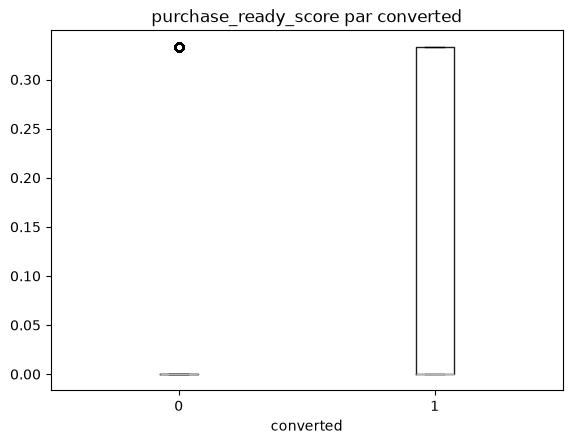

In [6]:
nlp.boxplot(column='purchase_ready_score', by='converted', grid=False)
plt.title('purchase_ready_score par converted'); plt.suptitle(''); plt.show()